### Notebook for exploring Self-Conditioned Knots for Probabilistic LiDAR Hazrad Fields

In [25]:
from vedo import *
settings.default_backend = "k3d"
import numpy as np
from scipy.spatial.transform import Rotation as R
import copy

from matplotlib import pyplot as p

%load_ext autoreload
%autoreload 2
%autosave 180

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Autosaving every 180 seconds


In [26]:
# Configure device (GPU if available)
import torch
from torch.utils.data import Dataset, DataLoader

# Reset default device to CPU to avoid DataLoader sampler conflicts
torch.set_default_device(None)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")
    print(f"Device count: {torch.cuda.device_count()}")
print(f"Using device: {device}")


CUDA available: True
Device name: NVIDIA GeForce RTX 3090
Device count: 1
Using device: cuda


## Generate synthetic LiDAR data

In [3]:
from synthetic_data_generation_utils import (
    LidarProjectionModel,
    Scene,
    generate_point_cloud,
)

# 1. LiDAR Intrinsics (e.g. 32-channel, 360-degree rotation)
sensor = LidarProjectionModel(
    elevation_min=-25.0,
    elevation_max=25.0,
    num_detectors=32,
    num_azimuth=360,
    max_range=30.0,
)

# 2. Build 10x10m Enclosed Scene
scene = Scene()
wall_density = 100.0  # Solid boundaries (near-surface returns)

# --- Floor & 4 Walls (10m x 10m x 3m interior) ---
scene.add_box(center=[0.0, 0.0, -0.1], size=[10.4, 10.4, 0.2], density=wall_density, name="floor")
scene.add_box(center=[0.0, 5.1, 1.5],  size=[10.4, 0.2, 3.0],  density=wall_density, name="wall_north")
scene.add_box(center=[0.0, -5.1, 1.5], size=[10.4, 0.2, 3.0],  density=wall_density, name="wall_south")
scene.add_box(center=[5.1, 0.0, 1.5],  size=[0.2, 10.4, 3.0],  density=wall_density, name="wall_east")
scene.add_box(center=[-5.1, 0.0, 1.5], size=[0.2, 10.4, 3.0],  density=wall_density, name="wall_west")

# --- 4 Cylinders (Pillars) with density = 1.0 ---
cyl_density = 1.0
scene.add_cylinder(center=[2.5, 2.5, 1.5],   radius=0.4, height=3.0, density=cyl_density, name="pillar_NE")
scene.add_cylinder(center=[-2.5, 2.5, 1.5],  radius=0.4, height=3.0, density=cyl_density, name="pillar_NW")
scene.add_cylinder(center=[2.5, -2.5, 1.5],  radius=0.4, height=3.0, density=cyl_density, name="pillar_SE")
scene.add_cylinder(center=[-2.5, -2.5, 1.5], radius=0.4, height=3.0, density=cyl_density, name="pillar_SW")

# --- Low-Density Spheres (Porous foliage / clutter with deep volumetric penetration) ---
scene.add_sphere(center=[2.0, 0.0, 1.0],   radius=0.8,  density=0.15, name="sphere_1")
scene.add_sphere(center=[-2.0, 0.5, 1.2],  radius=0.9,  density=0.10, name="sphere_2")
scene.add_sphere(center=[0.0, 3.0, 1.5],   radius=1.1,  density=0.08, name="sphere_3")
scene.add_sphere(center=[0.0, -2.8, 1.0],  radius=0.7,  density=0.20, name="sphere_4")
scene.add_sphere(center=[3.2, -1.8, 1.3],  radius=1.0,  density=0.12, name="sphere_5")
scene.add_sphere(center=[-3.0, -2.0, 1.4], radius=0.85, density=0.18, name="sphere_6")

# 3. Generate Point Cloud with the sensor positioned at the center of the room [0, 0, 1.5]
sensor_pos = [0.0, 0.0, 1.5]
point_cloud = generate_point_cloud(
    sensor=sensor,
    scene=scene,
    sensor_position=sensor_pos,
    method="sample",             # Stochastic sampling based on return probabilities
    return_placement="volume",   # Penetrable spheres have points distributed throughout their interior
    random_seed=42,
)

print(f"Generated {len(point_cloud)} points from {sensor.total_rays} rays.")
cloud_i = np.asarray(np.shape(point_cloud.points))
print(cloud_i)

# 4. Interactive 3D visualization with vedo
plt = Plotter(N=1, axes=1, bg=(1, 1, 1), interactive=True)
disp = scene.to_vedo(alpha=0.25)
disp.append(point_cloud.to_vedo(color_by="probability", cmap="viridis", point_size=3.5))
plt.show(disp, "10x10m Enclosed Room with Pillars and Low-Density Spheres")


Generated 9281 points from 11520 rays.
[9281    3]


## generate training data from multiple viewpoints

In [4]:
import numpy as np
from synthetic_data_generation_utils import compute_look_at_rotation

def generate_orbit_poses(num_poses: int = 16, radius: float = 3.0, height: float = 1.5, target=[0.0, 0.0, 1.2]):
    """Generates N sensor poses in a circular ring facing the center."""
    angles = np.linspace(0, 2 * np.pi, num_poses, endpoint=False)
    positions = []
    rotations = []
    
    for theta in angles:
        # Sensor position along the circle
        pos = np.array([radius * np.cos(theta), radius * np.sin(theta), height])
        # Aim the sensor forward (+X in sensor local frame) toward the target point
        rot = compute_look_at_rotation(eye=pos, target=target)
        positions.append(pos)
        rotations.append(rot)
        
    return np.array(positions), np.array(rotations)


In [5]:
from synthetic_data_generation_utils import (
    LidarProjectionModel, 
    Scene, 
    trace_scene_rays,
    rays_to_plucker,
    query_cdf_along_ray,
)

# 1. Setup Intrinsics & Scene (from your notebook)
sensor = LidarProjectionModel(elevation_min=-25.0, elevation_max=25.0, num_detectors=32, num_azimuth=180)
# scene = ... (your 10x10m box room from notebook)

# 2. Get N Poses
N_poses = 12
positions, rotations = generate_orbit_poses(num_poses=N_poses, radius=3.2, height=1.4)

# 3. Collect Ray Data from all viewpoints
all_rays_o = []
all_rays_d = []
all_hit_ranges = []
all_hit_masks = []
all_gt_cdfs = []

# Distances at which to evaluate ground-truth CDF for supervision (e.g. 64 knots from 0 to 15m)
eval_knots = np.linspace(0.1, 15.0, 64)

for i in range(N_poses):
    print(i)
    pos, rot = positions[i], rotations[i]
    rays_o, rays_d = sensor.get_rays(pos, rot, flatten=True)
    
    # Trace rays to get collision / return info
    trace_results = trace_scene_rays(rays_o, rays_d, scene, max_range=sensor.max_range)
    
    for r_idx, res in enumerate(trace_results):
        hits = res["hits"]
        if len(hits) > 0:
            # First return / primary hit range
            hit_range = hits[0]["t_in"]
            hit_mask = 1.0
        else:
            hit_range = sensor.max_range
            hit_mask = 0.0
            
        all_rays_o.append(rays_o[r_idx])
        all_rays_d.append(rays_d[r_idx])
        all_hit_ranges.append(hit_range)
        all_hit_masks.append(hit_mask)
        
        # Optional: Exact continuous ground-truth CDF(t) along the ray
        gt_cdf = query_cdf_along_ray(scene, rays_o[r_idx], rays_d[r_idx], query_distances=eval_knots)
        all_gt_cdfs.append(gt_cdf)

# Stack into consolidated arrays
rays_o = np.array(all_rays_o, dtype=np.float32)       # (N_total_rays, 3)
rays_d = np.array(all_rays_d, dtype=np.float32)       # (N_total_rays, 3)
hit_ranges = np.array(all_hit_ranges, dtype=np.float32) # (N_total_rays,)
hit_masks = np.array(all_hit_masks, dtype=np.float32)   # (N_total_rays,)
gt_cdfs = np.array(all_gt_cdfs, dtype=np.float32)       # (N_total_rays, 64)

# Plücker coordinates (d, m = o x d)
plucker_d, plucker_m = rays_to_plucker(rays_o, rays_d)
plucker = np.concatenate([plucker_d, plucker_m], axis=-1).astype(np.float32)  # (N_total_rays, 6)


0
1
2
3
4
5
6
7
8
9
10
11


In [27]:
#structure into torch dataset for training
class LidarRayDataset(Dataset):
    def __init__(
        self, 
        rays_o: np.ndarray, 
        rays_d: np.ndarray, 
        hit_ranges: np.ndarray, 
        hit_masks: np.ndarray, 
        gt_cdfs: np.ndarray,
        num_knots: int = 32,
        s_min: float = 0.1,
        s_max: float = 15.0,
        augment_origin_slide: bool = True,
    ):
        self.rays_o = torch.from_numpy(rays_o)
        self.rays_d = torch.from_numpy(rays_d)
        self.hit_ranges = torch.from_numpy(hit_ranges)
        self.hit_masks = torch.from_numpy(hit_masks)
        self.gt_cdfs = torch.from_numpy(gt_cdfs)
        
        self.num_knots = num_knots
        self.s_min = s_min
        self.s_max = s_max
        self.augment_origin_slide = augment_origin_slide
        # Fixed query grid matching the evaluation points of gt_cdfs
        self.eval_distances = np.linspace(s_min, s_max, gt_cdfs.shape[-1])

    def __len__(self):
        return len(self.rays_o)

    def __getitem__(self, idx):
        o = self.rays_o[idx].clone()
        d = self.rays_d[idx].clone()
        range_d = self.hit_ranges[idx].item()
        mask = self.hit_masks[idx].item()
        cdf_gt = self.gt_cdfs[idx].clone()

        # Origin-Sliding Augmentation: slide origin forward into empty space [0, range_d)
        if self.augment_origin_slide and range_d > self.s_min and np.random.rand() < 0.5:
            delta = float(np.random.uniform(0.0, 0.7 * range_d))
            o = o + delta * d
            range_d = max(0.0, range_d - delta)

            # Ground truth CDF at distance s' from the new origin o' corresponds to
            # distance (s' + delta) from the original origin o
            cdf_shifted = np.interp(
                self.eval_distances + delta,
                self.eval_distances,
                cdf_gt.numpy(),
                right=float(cdf_gt[-1]),
            )
            cdf_gt = torch.from_numpy(cdf_shifted.astype(np.float32))

        # Plücker coordinates: d and m = o x d
        m = torch.cross(o, d, dim=-1)
        plucker = torch.cat([d, m], dim=-1)

        # Uniform candidate knot distances for Round 0: s_k in [s_min, s_max]
        s_knots_0 = torch.linspace(self.s_min, self.s_max, self.num_knots)
        # World coordinates: x_k = o + s_k * d
        x_knots_0 = o.unsqueeze(0) + s_knots_0.unsqueeze(-1) * d.unsqueeze(0)  # Shape (K, 3)

        return {
            "ray_o": o,               # (3,)
            "ray_d": d,               # (3,)
            "plucker": plucker,       # (6,)
            "x_knots_0": x_knots_0,   # (K, 3)
            "s_knots_0": s_knots_0,   # (K,)
            "hit_range": torch.tensor(range_d, dtype=torch.float32),
            "hit_mask": torch.tensor(mask, dtype=torch.float32),
            "gt_cdf": cdf_gt,         # (64,)
        }

# Define the network

In [28]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

class PositionalEncoding(nn.Module):
    """
    Scene-scaled sinusoidal positional encoding.
    
    Normalizes coordinates by max_coord so the lowest frequency spans the 
    entire scene (wavelength = 2 * max_coord), avoiding spatial aliasing.
    """
    def __init__(self, in_dim: int, num_freqs: int = 8, max_coord: float = 15.0):
        super().__init__()
        self.num_freqs = num_freqs
        self.max_coord = max_coord
        
        # Frequencies from 2^0 to 2^(num_freqs - 1)
        freqs = 2.0 ** torch.linspace(0, num_freqs - 1, num_freqs)
        self.register_buffer("freqs", freqs)
        self.out_dim = in_dim + in_dim * 2 * num_freqs

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Normalize into [-1, 1] relative to scene scale
        x_norm = x / self.max_coord
        out = [x_norm]
        
        for f in self.freqs:
            out.append(torch.sin(f * math.pi * x_norm))
            out.append(torch.cos(f * math.pi * x_norm))
            
        return torch.cat(out, dim=-1)

class DeeperSCKNetwork(nn.Module):
    """
    Self-Conditioned Knot Network with True Residual Knot Flow.
    
    In Round 0, knots start uniformly distributed across [s_min, s_max].
    In subsequent rounds, the network predicts local residual displacements (shifts)
    that physically nudge candidate knots toward high-gradient / obstacle boundaries,
    refining knot placement iteratively.
    """
    def __init__(
        self,
        num_knots: int = 32,
        s_min: float = 0.1,
        s_max: float = 15.0,
        hidden_dim: int = 128,
        num_hidden_blocks: int = 3,
        num_rounds: int = 2,
        max_displacement: float = 0.6,
    ):
        super().__init__()
        self.num_knots = num_knots
        self.s_min = s_min
        self.s_max = s_max
        self.num_rounds = num_rounds
        self.max_displacement = max_displacement

        # 1. Positional encoders for high-frequency 3D coordinates
        self.pos_enc_x = PositionalEncoding(in_dim=3, num_freqs=6)
        self.pos_enc_ray = PositionalEncoding(in_dim=9, num_freqs=4)

        self.ray_in = nn.Sequential(
            nn.Linear(self.pos_enc_ray.out_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )

        self.knot_in = nn.Sequential(
            nn.Linear(self.pos_enc_x.out_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )

        # 2. Deeper residual decoder trunk
        self.joint_in = nn.Linear(hidden_dim * 2, hidden_dim)
        self.res_blocks = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim),
            )
            for _ in range(num_hidden_blocks)
        ])

        # Channel 0: Knot displacement shift (residual flow)
        # Channel 1: Local volumetric density (hazard)
        self.out_head = nn.Linear(hidden_dim, 2)

        # Initial biases: 0 displacement shift at start, low initial free-space density
        with torch.no_grad():
            self.out_head.bias[0].fill_(0.0)
            self.out_head.bias[1].fill_(-4.0)

    def forward_single_pass(self, ray_o: torch.Tensor, ray_d: torch.Tensor, s_knots: torch.Tensor):
        B, K = s_knots.shape

        # Ray encoding
        ray_m = torch.cross(ray_o, ray_d, dim=-1)
        ray_input = torch.cat([ray_o, ray_d, ray_m], dim=-1)
        ray_feat = F.relu(self.ray_in(self.pos_enc_ray(ray_input)))

        # 3D Knot position encoding evaluated at CURRENT knot coordinates
        x_knots = ray_o.unsqueeze(1) + s_knots.unsqueeze(-1) * ray_d.unsqueeze(1)
        knot_feat = F.relu(self.knot_in(self.pos_enc_x(x_knots)))

        # Joint features through residual trunk
        ray_feat_expanded = ray_feat.unsqueeze(1).expand(-1, K, -1)
        h = F.relu(self.joint_in(torch.cat([ray_feat_expanded, knot_feat], dim=-1)))

        for block in self.res_blocks:
            h = F.relu(h + block(h))

        out = self.out_head(h)
        
        # 1. Residual Knot Displacement (Flow): nudge candidate knots locally
        shift = torch.tanh(out[..., 0]) * self.max_displacement
        shifted_s = s_knots + shift
        shifted_s = torch.clamp(shifted_s, self.s_min, self.s_max)
        
        # Maintain monotonic ordering along ray
        new_s_knots, _ = torch.sort(shifted_s, dim=-1)

        # 2. Compute hazard intervals between sorted knots
        density = F.softplus(out[..., 1])
        s_boundary = torch.full((B, 1), self.s_min, device=ray_o.device)
        delta_s = new_s_knots - torch.cat([s_boundary, new_s_knots[:, :-1]], dim=-1)
        delta_s = torch.clamp(delta_s, min=1e-4)

        hazard_increments = density * delta_s
        cum_hazard = torch.cumsum(hazard_increments, dim=-1)
        c_knots = 1.0 - torch.exp(-cum_hazard)

        return new_s_knots, c_knots, shift, density

    def forward(self, ray_o: torch.Tensor, ray_d: torch.Tensor):
        B = ray_o.shape[0]
        # Start Round 0 with clean, uniformly spaced candidate knots across [s_min, s_max]
        s_knots = torch.linspace(self.s_min, self.s_max, self.num_knots, device=ray_o.device)
        s_knots = s_knots.unsqueeze(0).expand(B, -1)

        outputs = []
        for r in range(self.num_rounds):
            s_knots, c_knots, shift, density = self.forward_single_pass(ray_o, ray_d, s_knots)
            outputs.append((s_knots, c_knots))
            # Feed refined knot positions into next round of self-conditioning
            s_knots = s_knots.detach()

        return s_knots, c_knots, outputs


In [29]:
def interpolate_cdf_to_grid(s_knots: torch.Tensor, c_knots: torch.Tensor, eval_grid: torch.Tensor):
    """
    Interpolates predicted CDF (s_knots, c_knots) onto a fixed query grid (M,).
    
    s_knots: (B, K)
    c_knots: (B, K)
    eval_grid: (M,)
    Returns: (B, M) interpolated CDF values
    """
    B, K = s_knots.shape
    M = eval_grid.shape[0]
    
    # Expand grid to (B, M)
    query = eval_grid.unsqueeze(0).expand(B, -1)
    
    # Prepend boundary knot (s=0, C=0)
    s_zero = torch.zeros(B, 1, device=s_knots.device)
    c_zero = torch.zeros(B, 1, device=c_knots.device)
    s_ext = torch.cat([s_zero, s_knots], dim=-1)  # (B, K+1)
    c_ext = torch.cat([c_zero, c_knots], dim=-1)  # (B, K+1)

    # Find bin indices using searchsorted
    idx = torch.searchsorted(s_ext.contiguous(), query.contiguous(), right=True)
    idx = torch.clamp(idx, 1, K)  # Keep valid range

    # Gather adjacent control points
    idx_left = idx - 1
    s_0 = torch.gather(s_ext, 1, idx_left)
    s_1 = torch.gather(s_ext, 1, idx)
    c_0 = torch.gather(c_ext, 1, idx_left)
    c_1 = torch.gather(c_ext, 1, idx)

    # Linear interpolation weight
    denom = torch.clamp(s_1 - s_0, min=1e-5)
    alpha = torch.clamp((query - s_0) / denom, 0.0, 1.0)
    
    c_interp = c_0 + alpha * (c_1 - c_0)
    return c_interp


# Train Loop

### Notes: Self-Conditioned Residual Knot Flow

In true Self-Conditioning:
1. **Initial State (Round 0)**: Knots start cleanly and uniformly distributed across $[s_{\min}, s_{\max}]$ ($[0.1\text{m}, 15.0\text{m}]$).
2. **Residual Knot Flow**: Rather than re-generating absolute knot positions via an unconstrained global softmax from scratch every pass, the network outputs a local displacement field $\delta s_k = \tanh(\text{out}_0) \times d_{\max}$ that physically nudges candidate knots toward high-hazard / surface boundaries ($s^{(r+1)} = \text{sort}(s^{(r)} + \delta s)$).
3. **Self-Conditioning Refinement**: Subsequent rounds evaluate features at the updated knot positions, allowing knots to bracket sharp jumps tightly while empty regions stay naturally uniform.


In [47]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DeeperSCKNetwork(num_knots=32, num_rounds=2, max_displacement=0.6).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# The fixed 64 evaluation grid points (from dataset)
eval_grid = torch.linspace(0.1, 15.0, 64, device=device)
dt = (15.0 - 0.1) / (64 - 1)

def train_step(batch):
    model.train()
    optimizer.zero_grad()

    ray_o = batch["ray_o"].to(device)       # (B, 3)
    ray_d = batch["ray_d"].to(device)       # (B, 3)
    gt_cdf = batch["gt_cdf"].to(device)     # (B, 64)

    # Forward pass through self-conditioning rounds
    s_final, c_final, round_outputs = model(ray_o, ray_d)

    total_loss = 0.0
    num_r = len(round_outputs)
    weights = [0.5 ** (num_r - 1 - i) for i in range(num_r)]

    for (s_round, c_round), w in zip(round_outputs, weights):
        # 1. Project predicted continuous curve onto the 64 evaluation points
        pred_grid = interpolate_cdf_to_grid(s_round, c_round, eval_grid)
        
        # 2. Continuous L2 / CRPS loss scaled by bin width dt
        round_l2_loss = dt * torch.sum((pred_grid - gt_cdf) ** 2, dim=-1).mean()
        total_loss += w * round_l2_loss

    total_loss.backward()
    optimizer.step()

    return total_loss.item()


Training on cuda (69120 rays, 68 batches/epoch)...
Epoch [01/100] - Loss: 7.517765
Epoch [02/100] - Loss: 2.433021
Epoch [03/100] - Loss: 1.869696
Epoch [04/100] - Loss: 1.292438
Epoch [05/100] - Loss: 0.710007
Epoch [06/100] - Loss: 0.340452
Epoch [07/100] - Loss: 0.253460
Epoch [08/100] - Loss: 0.222536
Epoch [09/100] - Loss: 0.200708
Epoch [10/100] - Loss: 0.188216
Epoch [11/100] - Loss: 0.178172
Epoch [12/100] - Loss: 0.170084
Epoch [13/100] - Loss: 0.164801
Epoch [14/100] - Loss: 0.159125
Epoch [15/100] - Loss: 0.151600
Epoch [16/100] - Loss: 0.135847
Epoch [17/100] - Loss: 0.122410
Epoch [18/100] - Loss: 0.116567
Epoch [19/100] - Loss: 0.109984
Epoch [20/100] - Loss: 0.105955
Epoch [21/100] - Loss: 0.101628
Epoch [22/100] - Loss: 0.096948
Epoch [23/100] - Loss: 0.093850
Epoch [24/100] - Loss: 0.091756
Epoch [25/100] - Loss: 0.088688
Epoch [26/100] - Loss: 0.086455
Epoch [27/100] - Loss: 0.083403
Epoch [28/100] - Loss: 0.081934
Epoch [29/100] - Loss: 0.080824
Epoch [30/100] - Loss

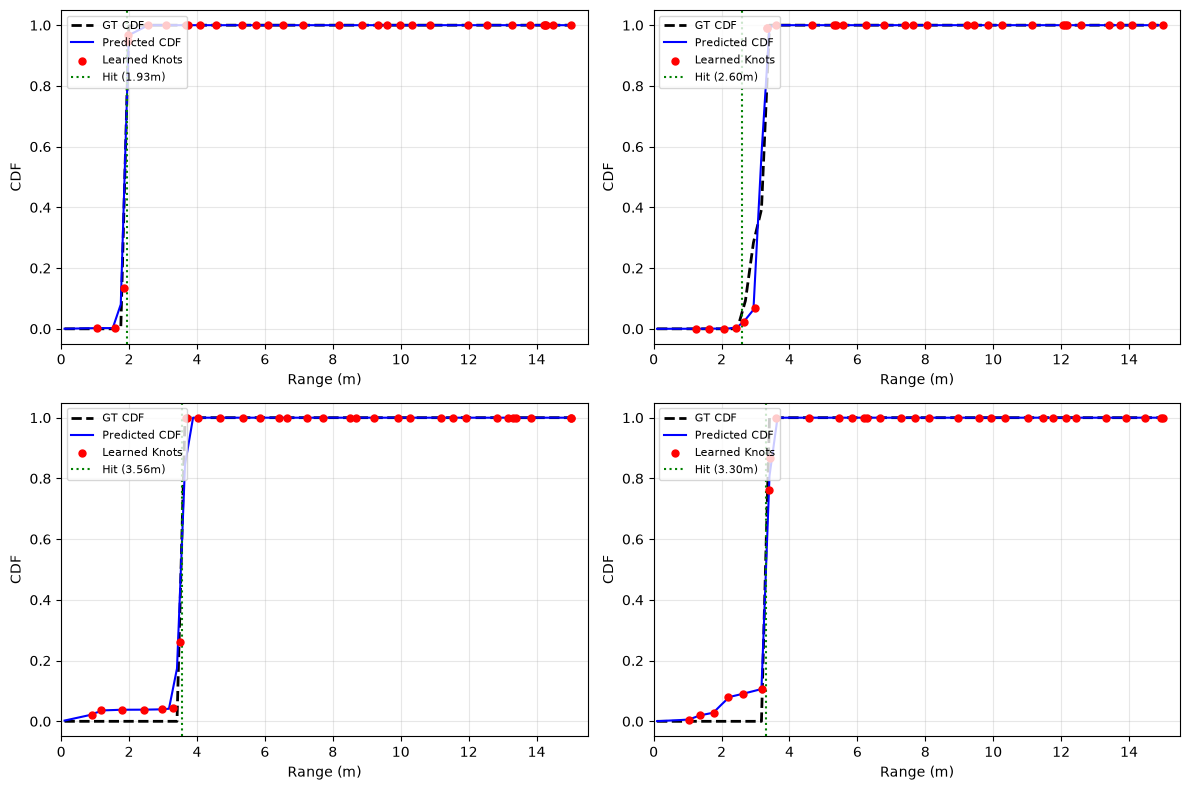

In [48]:
import matplotlib.pyplot as plt
import math

# 1. Instantiate Dataset and DataLoader
dataset = LidarRayDataset(
    rays_o=rays_o,
    rays_d=rays_d,
    hit_ranges=hit_ranges,
    hit_masks=hit_masks,
    gt_cdfs=gt_cdfs,
    augment_origin_slide=False, #default True
)
dataloader = DataLoader(
    dataset, 
    batch_size=1024,       # Larger batch size uses the RTX 3090 much better
    shuffle=True, 
    num_workers=4,        # 4 parallel CPU worker processes
    persistent_workers=True,
    pin_memory=True       # Speeds up CPU-to-GPU memory transfer
)

# 2. Run Training Loop
num_epochs = 100
print(f"Training on {device} ({len(dataset)} rays, {len(dataloader)} batches/epoch)...")

for epoch in range(num_epochs):
    epoch_loss = 0.0
    for batch in dataloader:
        loss = train_step(batch)
        epoch_loss += loss

    avg_loss = epoch_loss / len(dataloader)
    print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] - Loss: {avg_loss:.6f}")

# 3. Visualize Learned Knot Placements vs Ground Truth CDF
model.eval()
with torch.no_grad():
    sample_indices = [0, 50, 150, 300]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    for ax, idx in zip(axes.flat, sample_indices):
        sample = dataset[idx]
        o = sample["ray_o"].unsqueeze(0).to(device)
        d = sample["ray_d"].unsqueeze(0).to(device)
        gt = sample["gt_cdf"].cpu().numpy()

        s_knots, c_knots, _ = model(o, d)
        s_k = s_knots[0].cpu().numpy()
        c_k = c_knots[0].cpu().numpy()
        pred_interp = interpolate_cdf_to_grid(s_knots, c_knots, eval_grid)[0].cpu().numpy()
        eval_pts = eval_grid.cpu().numpy()

        ax.plot(eval_pts, gt, 'k--', label='GT CDF', linewidth=2)
        ax.plot(eval_pts, pred_interp, 'b-', label='Predicted CDF')
        ax.scatter(s_k, c_k, color='red', s=25, zorder=5, label='Learned Knots')
        if sample["hit_mask"] > 0:
            ax.axvline(sample["hit_range"].item(), color='green', linestyle=':', label=f'Hit ({sample["hit_range"]:.2f}m)')

        ax.set_xlim(0.0, 15.5)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel("Range (m)")
        ax.set_ylabel("CDF")
        ax.legend(loc="upper left", fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


# Make cloud at novel position

In [51]:
import torch
import numpy as np
from synthetic_data_generation_utils import PointCloud
from vedo import Plotter

def generate_point_cloud_from_network(
    model,
    sensor,
    sensor_position=[0.0, 0.0, 1.5],
    sensor_rotation=None,
    method="threshold",  # "threshold" for surface hits, or "sample" for stochastic returns
    threshold=0.5,       # CDF threshold (0.5 = median return distance)
    batch_size=1024,
    device=device,
) -> PointCloud:
    """
    Renders a 3D PointCloud by passing sensor rays through the trained SCKNetwork
    and inverting the predicted continuous return CDF along each ray.
    """
    model.eval()

    # 1. Generate full ray grid from the LiDAR projection model
    rays_o_np, rays_d_np = sensor.get_rays(
        sensor_position=sensor_position,
        sensor_rotation=sensor_rotation,
        flatten=True,
    )
    total_rays = len(rays_o_np)

    all_points = []
    all_probs = []
    all_ranges = []
    all_rays_d = []
    all_rays_o = []

    with torch.no_grad():
        for i in range(0, total_rays, batch_size):
            batch_o = torch.from_numpy(rays_o_np[i : i + batch_size]).float().to(device)
            batch_d = torch.from_numpy(rays_d_np[i : i + batch_size]).float().to(device)
            B = batch_o.shape[0]

            # 2. Predict knot distances and CDF values
            s_knots, c_knots, _ = model(batch_o, batch_d)  # (B, K)
            K = s_knots.shape[1]

            # 3. Prepend boundary knot (s=0, C=0)
            s_zero = torch.zeros(B, 1, device=device)
            c_zero = torch.zeros(B, 1, device=device)
            s_ext = torch.cat([s_zero, s_knots], dim=-1)   # (B, K+1)
            c_ext = torch.cat([c_zero, c_knots], dim=-1)   # (B, K+1)
            c_max = c_ext[:, -1]

            # 4. Target CDF values for inversion
            if method == "threshold":
                target = torch.full((B, 1), threshold, device=device)
                valid_mask = (c_max >= threshold).squeeze(-1)
            elif method == "sample":
                u = torch.rand(B, 1, device=device)
                valid_mask = (u.squeeze(-1) <= c_max)
                target = u
            else:
                raise ValueError(f"Unknown method '{method}'. Use 'threshold' or 'sample'.")

            # 5. Invert piecewise linear CDF to solve for exact return range s*
            idx = torch.searchsorted(c_ext.contiguous(), target.contiguous(), right=True)
            idx = torch.clamp(idx, 1, K)

            idx_left = idx - 1
            s_0 = torch.gather(s_ext, 1, idx_left).squeeze(-1)
            s_1 = torch.gather(s_ext, 1, idx).squeeze(-1)
            c_0 = torch.gather(c_ext, 1, idx_left).squeeze(-1)
            c_1 = torch.gather(c_ext, 1, idx).squeeze(-1)

            denom = torch.clamp(c_1 - c_0, min=1e-5)
            alpha = torch.clamp((target.squeeze(-1) - c_0) / denom, 0.0, 1.0)
            pred_ranges = s_0 + alpha * (s_1 - s_0)

            # 6. Compute 3D Cartesian coordinates: p = o + s* * d
            pts = batch_o + pred_ranges.unsqueeze(-1) * batch_d

            # Keep only rays that produced valid returns
            if valid_mask.any():
                all_points.append(pts[valid_mask].cpu().numpy())
                all_probs.append(c_max[valid_mask].cpu().numpy())
                all_ranges.append(pred_ranges[valid_mask].cpu().numpy())
                all_rays_d.append(batch_d[valid_mask].cpu().numpy())
                all_rays_o.append(batch_o[valid_mask].cpu().numpy())

    if len(all_points) == 0:
        print("Warning: No returns met the threshold!")
        return PointCloud(np.empty((0, 3)), np.empty(0), np.empty(0))

    points = np.concatenate(all_points, axis=0)
    probs = np.concatenate(all_probs, axis=0)
    ranges = np.concatenate(all_ranges, axis=0)
    rays_d = np.concatenate(all_rays_d, axis=0)
    rays_o = np.concatenate(all_rays_o, axis=0)

    print(f"Generated {len(points)} points from {total_rays} rays ({len(points)/total_rays*100:.1f}% return rate).")

    return PointCloud(
        points=points,
        probabilities=probs,
        ranges=ranges,
        ray_directions=rays_d,
        rays_o=rays_o,
    )


# ==============================================================================
# Execute Inference and Draw
# ==============================================================================

# 1. Generate point cloud with the sensor placed at room center [0, 0, 1.5]
pred_cloud = generate_point_cloud_from_network(
    model=model,
    sensor=sensor,
    sensor_position=[0.0, 0.0, 1.5],
    # method= 'sample', #"threshold",  # or "sample"
    method= "threshold",  # or "sample"
    threshold=0.5,
)

# 2. 3D interactive visualization with Vedo (overlaid on scene geometry)
plt_vedo = Plotter(N=1, axes=1, bg=(1, 1, 1), interactive=True)
disp = scene.to_vedo(alpha=0.15)

disp.append(pred_cloud.to_vedo(color_by="range", cmap="plasma", point_size=3.5))
plt_vedo.show(disp, "Network Reconstructed Point Cloud")

Generated 4630 points from 5760 rays (80.4% return rate).


In [ ]:
print("Model device:", next(model.parameters()).device)
print(f"Allocated VRAM: {torch.cuda.memory_allocated() / (1024**2):.2f} MB")